# Fraud Detection: Hypotheses, Gas vs Electricity

**Goal:** Check every hypothesis from [06_eda-analysis.ipynb](06_eda-analysis.ipynb) again, but **separately for electricity (ELEC) and gas (GAZ)**, so we can see if a hypothesis holds for both meters or only for one.

How to read this notebook:
- Same approach as in `06_eda-analysis.ipynb`: a short explanation before each code cell, an **Insight** after the output.
- Every table has two blocks of columns, **ELEC** and **GAZ**. Every chart has two panels: **ELEC (blue, left)** and **GAZ (orange, right)**.
- The hypotheses have the same numbers and order as in [hypotheses.md](hypotheses.md).

We use the cleaned files in `data/clean/` (made by `cleaning.py`). Only the **train** tables have the fraud label (`target`), so all tests use train.

## 1. Load the data

In [1]:
# libraries for tables, numbers and charts
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# show up to 30 columns, so wide tables are not cut
pd.set_option("display.max_columns", 30)

# load the cleaned train files from cleaning.py (only train has the fraud label)
CLEAN_DIR = "data/clean"
client_train = pd.read_csv(f"{CLEAN_DIR}/client_train_clean.csv", parse_dates=["creation_date"])
invoice_train = pd.read_csv(f"{CLEAN_DIR}/invoice_train_clean.csv", parse_dates=["invoice_date"], low_memory=False)

# quick check of the table sizes (rows, columns)
print("client_train: ", client_train.shape)
print("invoice_train:", invoice_train.shape)

client_train:  (135493, 6)
invoice_train: (4476749, 16)


## 2. How we split the data into gas and electricity

**Important:** the fraud label `target` belongs to the **client**, not to a meter. A client can have an electricity meter, a gas meter, or both. So we cannot say *which* meter was manipulated. What we can do:

- For **ELEC**: take every client who has at least one electricity bill. Calculate all features **only from the electricity bills** of that client.
- For **GAZ**: the same with the gas bills.

A client with both meters appears in **both** analyses (once with his or her electricity bills, once with the gas bills). The fraud label is the same in both.

First we build one table with **one row per client and meter**, with all the values we need for the hypotheses. The code follows `06_eda-analysis.ipynb`, but every calculation is done **per meter**.

In [2]:
# the two meter types and the color of each meter in the charts
meters = ["ELEC", "GAZ"]
COLORS = {"ELEC": "tab:blue", "GAZ": "tab:orange"}

# total consumption of a bill = the four consumption levels added up
consumption_cols = [f"consommation_level_{i}" for i in range(1, 5)]
invoice_train["consumption"] = invoice_train[consumption_cols].sum(axis=1)

# jumps between two bills in a row, within one physical meter (as in the notebook 06)
meter_key = ["client_id", "counter_type", "counter_number"]
invoice_train = invoice_train.sort_values(meter_key + ["invoice_date"])
invoice_train["change"] = invoice_train.groupby(meter_key)["consumption"].diff().abs()

# index checks (hypotheses 3 and 6)
invoice_train["index_diff"] = invoice_train["new_index"] - invoice_train["old_index"]
# mismatch: the index difference is not the same as the billed consumption
invoice_train["mismatch"] = (invoice_train["index_diff"] != invoice_train["consumption"]).astype(int)
# backward: the new index is smaller than the old one
invoice_train["backward"] = (invoice_train["index_diff"] < 0).astype(int)
# a normal rollover: the meter starts close to its maximum (for example 99,999) and ends close to 0.
# The maximum depends on the number of digits of the meter (9,999 / 99,999 / 999,999), so we take the next power of 10.
meter_max = 10 ** np.ceil(np.log10(invoice_train["old_index"] + 1))
invoice_train["rollover"] = ((invoice_train["backward"] == 1)
                             & (invoice_train["old_index"] >= 0.9 * meter_max)
                             & (invoice_train["new_index"] <= 0.1 * meter_max)).astype(int)
# backward bills that are not explained by a rollover
invoice_train["backward_other"] = ((invoice_train["backward"] == 1) & (invoice_train["rollover"] == 0)).astype(int)

# one row per client AND meter type
per_meter = invoice_train.groupby(["client_id", "counter_type"]).agg(
    n_bills=("consumption", "size"),
    max_change=("change", "max"),
    std_cons=("consumption", "std"),
    mismatch_count=("mismatch", "sum"),
    backward_count=("backward", "sum"),
    backward_other_count=("backward_other", "sum"),
    max_consumption=("consumption", "max"),
).reset_index()

# add the fraud label and client info, then yes/no flags and the bill groups from notebook 06
per_meter = per_meter.merge(client_train[["client_id", "target", "region", "client_catg"]], on="client_id")
per_meter["has_mismatch"] = per_meter["mismatch_count"] > 0
per_meter["has_backward"] = per_meter["backward_count"] > 0
per_meter["has_backward_other"] = per_meter["backward_other_count"] > 0
per_meter["bill_group"] = pd.cut(per_meter["n_bills"], [0, 10, 30, 50, 1000],
                                 labels=["1 to 10", "11 to 30", "31 to 50", "51 or more"])

# one table for each meter
data = {m: per_meter[per_meter["counter_type"] == m].copy() for m in meters}
# fraud rate of all clients with this meter (the red line in the charts)
base = {m: data[m]["target"].mean() for m in meters}

### Helper functions

The same few steps come back in every hypothesis (fraud rate and number of clients per group, one chart with ELEC and GAZ side by side). We write them once.

- `rate_table(df, col)`: fraud rate (%) and number of clients for each value of `col`.
- `side_by_side(tables, ...)`: two bar charts next to each other, ELEC left and GAZ right, with the same y-axis. The red line is the fraud rate of **all clients who have this meter** (the reference for that panel).

In [3]:
# fraud rate (%) and number of clients for each value of col
def rate_table(df, col):
    t = df.groupby(col, observed=True)["target"].agg(["mean", "count"])
    t["fraud_%"] = (t["mean"] * 100).round(1)
    return t.rename(columns={"count": "clients"})[["clients", "fraud_%"]]


# two bar charts, ELEC left and GAZ right, with the same y-axis
def side_by_side(tables, xlabel, title, figsize=(11, 4), rot=0):
    fig, axes = plt.subplots(1, 2, figsize=figsize, sharey=True)
    for ax, m in zip(axes, meters):
        t = tables[m]["fraud_%"].dropna()
        t.plot(kind="bar", ax=ax, color=COLORS[m], rot=rot)
        ax.bar_label(ax.containers[0], fmt="%.1f%%")
        # red line: fraud rate of all clients with this meter, the reference for this panel
        ax.axhline(base[m] * 100, color="red", linestyle="--", label=f"all {m} clients ({base[m] * 100:.1f}%)")
        ax.set_title(m)
        ax.set_xlabel(xlabel)
        ax.legend()
    axes[0].set_ylabel("fraud rate (%)")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

## 3. First look: how different are the two meters?

For each meter we count the clients and bills, and the fraud rate of the clients who have this meter.

In [4]:
# clients, fraud clients, fraud rate and bills for each meter
overview = pd.DataFrame({
    m: {
        "clients": len(data[m]),
        "fraud clients": int(data[m]["target"].sum()),
        "fraud rate %": round(base[m] * 100, 1),
        "bills": int(data[m]["n_bills"].sum()),
        "median bills per client": data[m]["n_bills"].median(),
    }
    for m in meters
})
# the same numbers for the whole train set, to compare
overview["all clients"] = [len(client_train), int(client_train["target"].sum()),
                           round(client_train["target"].mean() * 100, 1), len(invoice_train),
                           invoice_train.groupby("client_id").size().median()]
overview

,ELEC,GAZ,all clients
clients,134815.0,62054.0,135493.0
fraud clients,7560.0,4447.0,7566.0
fraud rate %,5.6,7.2,5.6
bills,3079406.0,1397343.0,4476749.0
median bills per client,23.0,23.0,30.0


**Insight:**
- Almost every client (134,815 of 135,493) has an electricity meter, so the **ELEC numbers are close to the numbers of the whole train set**. Gas is the smaller group: 62,054 clients. About 61,000 clients have both meters.
- Clients with a gas meter have a **higher fraud rate: 7.2%** against 5.6% for electricity. So the red line in the charts is **not the same** for the two panels. Always compare a bar with the red line of its own panel.
- The typical client has the same number of bills on both meters (median 23).
- Remember: the label belongs to the client. A fraud client with both meters counts as fraud in both columns.

## 4. First check: does the number of bills matter for each meter?

*Our data analyst agent found that the number of bills explains a part of many effects, so we check it again for each meter.* We count the bills of each client **on that meter** and use the same four groups as in notebook 06.

In [5]:
# fraud rate per bill group for each meter, ELEC and GAZ columns side by side
bill_results = {m: rate_table(data[m], "bill_group") for m in meters}
pd.concat(bill_results, axis=1)

ELEC             GAZ        
           clients fraud_% clients fraud_%
bill_group                                
1 to 10      37604     1.6   11657     3.5
11 to 30     49678     5.8   33180     7.4
31 to 50     44596     8.2   16870     8.9
51 or more    2937    14.3     347    24.2

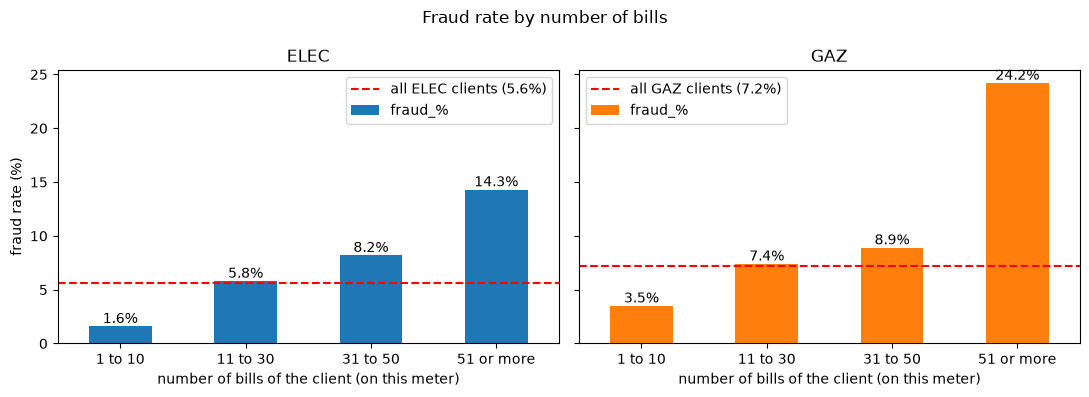

In [6]:
# chart: fraud rate per bill group, ELEC left and GAZ right
side_by_side(bill_results, "number of bills of the client (on this meter)", "Fraud rate by number of bills")

**Insight:**
- On both meters the fraud rate **goes up with the number of bills**: ELEC 1.6%, 5.8%, 8.2%, 14.3% and GAZ 3.5%, 7.4%, 8.9%, 24.2%.
- Gas is a little higher in every group. The last gas group (51 or more) has only 347 clients, so 24.2% is not very reliable.
- Counting the bills per meter splits a client's bills in two, so fewer clients land in the top group than in notebook 06 (2,937 for ELEC).

**Next step:** Use `n_bills` as a feature, and also the number of bills per meter (`n_bills_elec`, `n_bills_gaz`).

## Hypothesis 1: the fraud rate differs by region

**Idea:** some regions have more fraud than others. We calculate the fraud rate of every region, **once for the clients with an electricity meter and once for the clients with a gas meter**. In the chart we only show regions with at least 500 clients on that meter, because rates from fewer clients are not reliable.

In [7]:
# fraud rate per region for each meter, biggest ELEC regions first
region_results = {m: rate_table(data[m], "region") for m in meters}
region_table = pd.concat(region_results, axis=1).sort_values(("ELEC", "clients"), ascending=False)
region_table

ELEC             GAZ        
        clients fraud_% clients fraud_%
region                                 
101     33342.0     3.6   14210     4.6
104     12761.0     5.6    7320     6.3
311     12397.0     8.1    7499     9.9
107      9980.0     6.6    5330     7.8
301      9529.0     3.3    3797     3.2
103      8930.0    10.3    5724    12.5
306      6038.0     4.9    2690     7.6
303      5978.0     5.5    2475     7.2
310      4847.0     5.1    1989     6.1
312      4370.0     5.0    1836     6.6
302      4300.0     6.2    1468     7.6
304      3821.0     6.7    1922     8.3
309      3663.0     4.3    1630     5.8
307      3376.0     6.2     353     7.4
305      2705.0     5.8    1027     6.8
313      2076.0     7.1     887    10.8
371      2065.0     7.2       1     0.0
105      1639.0     5.6     946     7.4
308       841.0     7.3     272     9.9
106       703.0     7.5     410     8.5
372       643.0    10.0      70     7.1
379       583.0     6.7     123     7.3
399       175.0     0.6      28     3.6
206        53.0     1.9      45     2.2
199         NaN     NaN       2     0.0

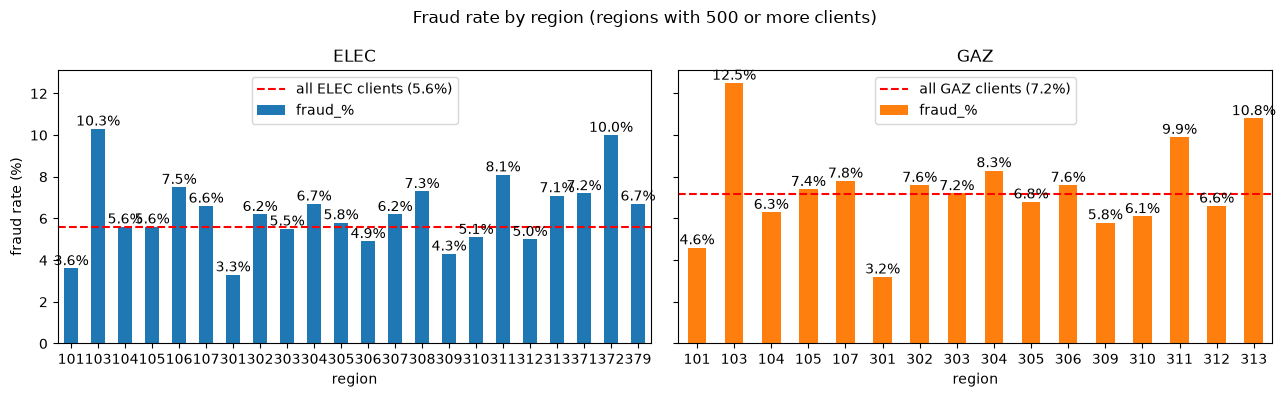

In [8]:
# only regions with at least 500 clients on that meter, because rates from fewer clients are not reliable
big_regions = {m: region_results[m][region_results[m]["clients"] >= 500].sort_index() for m in meters}
side_by_side(big_regions, "region", "Fraud rate by region (regions with 500 or more clients)", figsize=(13, 4))

Do the two meters rank the regions in the same way? We compare the fraud rates of the regions that are big enough on both meters (rank correlation: 1 = same order, 0 = no link).

In [9]:
# keep only the regions that are big enough on both meters
common = pd.concat(big_regions, axis=1).dropna()
common.columns = ["ELEC clients", "ELEC fraud_%", "GAZ clients", "GAZ fraud_%"]
# spearman rank correlation: 1 = same order of regions on both meters, 0 = no link
print("regions in both:", len(common))
print("rank correlation of the region fraud rates:", round(common["ELEC fraud_%"].corr(common["GAZ fraud_%"], method="spearman"), 2))
common.sort_values("ELEC fraud_%", ascending=False)

regions in both: 16


rank correlation of the region fraud rates: 0.89


,ELEC clients,ELEC fraud_%,GAZ clients,GAZ fraud_%
region,,,,
103,8930,10.3,5724.0,12.5
311,12397,8.1,7499.0,9.9
313,2076,7.1,887.0,10.8
304,3821,6.7,1922.0,8.3
107,9980,6.6,5330.0,7.8
302,4300,6.2,1468.0,7.6
305,2705,5.8,1027.0,6.8
104,12761,5.6,7320.0,6.3
105,1639,5.6,946.0,7.4


**Insight:**
- Both meters show **the same picture**. Region **103** is the highest (ELEC 10.3%, GAZ 12.5%), then **311** (8.1% and 9.9%). Regions **101** (3.6% and 4.6%) and **301** (3.3% and 3.2%) are the lowest.
- The order of the regions is almost the same: the rank correlation is **0.89** (16 regions that are big enough on both meters).
- Gas rates are higher in most regions, which fits the higher gas average (7.2%). Only region 301 has the same low rate on both meters.
- Regions with very few clients on one meter (for example 371 with 1 gas client, or 199 with no electricity client) should be ignored.

**Result:** Supported for **both** meters, with the same pattern.
**Next step:** Keep `region` as a category feature. We do not need a separate region feature per meter.

## Hypothesis 2: a sudden change in consumption indicates fraud

**Idea:** fraud clients have a less steady consumption. For each client and meter we calculate `max_change` (the biggest jump between two bills in a row) and `std_cons` (the standard deviation of the bills), **using only the bills of this meter**. Then we compare the **median** of fraud and no-fraud clients.

In [10]:
# median of max_change and std_cons for fraud and no-fraud clients, per meter
change_result = pd.concat({m: data[m].groupby("target")[["max_change", "std_cons"]].median().round(0) for m in meters})
# readable row labels instead of 0 and 1
change_result.index = pd.MultiIndex.from_tuples(
    [(m, "fraud (1)" if t == 1 else "no fraud (0)") for m, t in change_result.index], names=["meter", "target"])
change_result

max_change  std_cons
meter target                            
ELEC  no fraud (0)       910.0     309.0
      fraud (1)         1492.0     462.0
GAZ   no fraud (0)       217.0      72.0
      fraud (1)          279.0      88.0

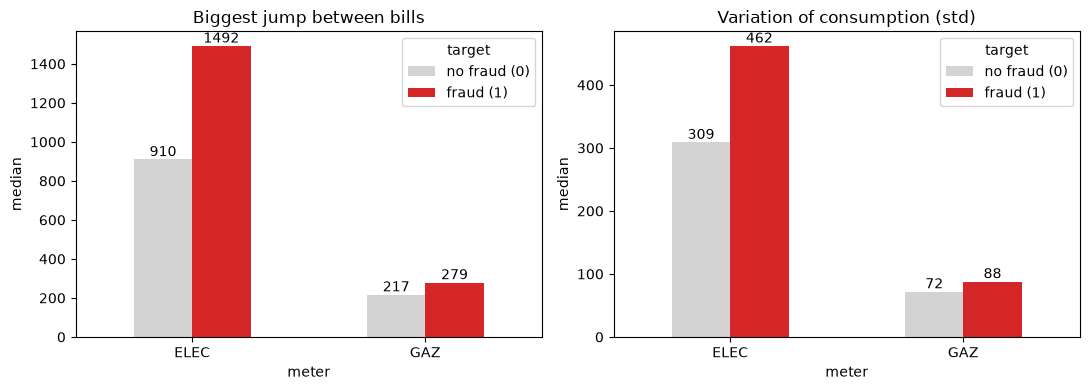

In [11]:
# one chart per measure: median of fraud vs no-fraud clients for each meter
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col, title in zip(axes, ["max_change", "std_cons"], ["Biggest jump between bills", "Variation of consumption (std)"]):
    t = change_result[col].unstack("target")[["no fraud (0)", "fraud (1)"]]
    t.plot(kind="bar", ax=ax, rot=0, color=["lightgrey", "tab:red"])
    # write the median on top of each bar
    for c in ax.containers:
        ax.bar_label(c, fmt="%d")
    ax.set_title(title)
    ax.set_xlabel("meter")
    ax.set_ylabel("median")
plt.tight_layout()
plt.show()

**Insight:**
- **ELEC:** the biggest jump is **1,492** for fraud clients and **910** for no-fraud clients (about **64% higher**). The standard deviation is 462 vs 309 (about 50% higher).
- **GAZ:** 279 vs 217 for the biggest jump (about **29% higher**) and 88 vs 72 for the standard deviation (about 22% higher).
- The direction is the same, but the effect is **clearly smaller for gas**. The gas numbers are much smaller overall (gas bills are smaller than electricity bills), so compare the percentages, not the numbers.

Now the check with a similar number of bills:

Now the same check with a similar number of bills, for each meter (median of the biggest jump):

In [12]:
# median of col for fraud and no-fraud clients inside each bill group
def median_by_group(df, col):
    t = df.groupby(["bill_group", "target"], observed=True)[col].median().unstack().round(0)
    t.columns = ["no fraud (0)", "fraud (1)"]
    return t

# biggest jump per bill group, so we compare clients with a similar number of bills
group_change = pd.concat({m: median_by_group(data[m], "max_change") for m in meters}, axis=1)
group_change

ELEC                    GAZ          
           no fraud (0) fraud (1) no fraud (0) fraud (1)
bill_group                                              
1 to 10           424.0    1428.0        121.0     205.0
11 to 30         1079.0    1837.0        220.0     288.0
31 to 50         1017.0    1248.0        257.0     264.0
51 or more       1842.0    2608.0       3436.0    3220.0

**Insight:**
- **ELEC:** fraud clients have the bigger jump in **every** bill group (for example 424 vs 1,428 for 1 to 10 bills, and 1,842 vs 2,608 for 51 or more).
- **GAZ:** fraud is higher for 1 to 10 bills (121 vs 205) and 11 to 30 bills (220 vs 288). For 31 to 50 bills the gap is gone (257 vs 264). For 51 or more it is even the other way round (3,436 vs 3,220), but that group has only 347 clients.

**Result:** Supported for **ELEC**, also with the same number of bills. **Weak for GAZ**: a small effect for clients with up to 30 bills, nothing after that.
**Next step:** Create `max_change` and `std_cons` for each meter (`max_change_elec`, `max_change_gaz`), and expect the electricity version to be the stronger one.

## Hypothesis 3: an index mismatch indicates fraud

For every bill, `new_index - old_index` should be the same as the four consumption levels added up. For each client and meter we count the bills where this is not true, and compare the fraud rate of clients with and without a mismatch.

In [13]:
# fraud rate of clients with and without an index mismatch, per meter
mismatch_results = {m: rate_table(data[m], "has_mismatch").rename(index={False: "no mismatch", True: "has mismatch"}) for m in meters}
pd.concat(mismatch_results, axis=1)

ELEC             GAZ        
             clients fraud_% clients fraud_%
has_mismatch                                
no mismatch   129849     5.5   58555     7.1
has mismatch    4966     9.2    3499     7.9

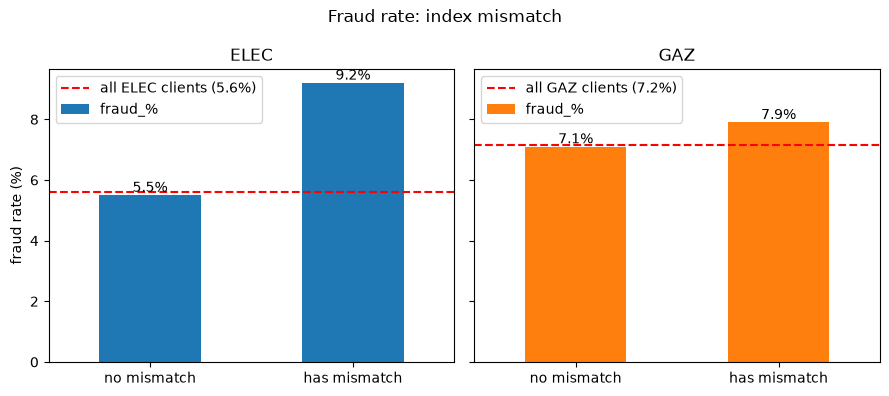

In [14]:
# chart: mismatch vs no mismatch, ELEC left and GAZ right
side_by_side(mismatch_results, "", "Fraud rate: index mismatch", figsize=(9, 4))

**Insight:**
- **ELEC:** clients with a mismatch have **9.2%** fraud (4,966 clients), without 5.5%. About 1.7 times more.
- **GAZ:** clients with a mismatch have **7.9%** (3,499 clients), without 7.1%. Almost no difference.

Check with a similar number of bills:

Inside each bill group (fraud rate in %):

In [15]:
# fraud rate (%) with and without a flag, inside each bill group
def rate_by_group(df, flag, names):
    t = (df.groupby(["bill_group", flag], observed=True)["target"].mean().unstack() * 100).round(1)
    t.columns = names
    return t

# check the mismatch effect with a similar number of bills
group_mismatch = pd.concat({m: rate_by_group(data[m], "has_mismatch", ["no mismatch", "has mismatch"]) for m in meters}, axis=1)
group_mismatch

ELEC                      GAZ             
           no mismatch has mismatch no mismatch has mismatch
bill_group                                                  
1 to 10            1.6          3.6         3.5          4.2
11 to 30           5.7          8.6         7.4          7.0
31 to 50           8.2          9.1         8.9          9.9
51 or more        14.2         14.4        24.5         22.4

**Insight:**
- **ELEC:** a small gap remains for clients with up to 30 bills (1.6% vs 3.6%, and 5.7% vs 8.6%). For 31 to 50 bills it is small (8.2% vs 9.1%) and for 51 or more it is gone (14.2% vs 14.4%).
- **GAZ:** no pattern. The mismatch group is sometimes higher and sometimes lower (7.4% vs 7.0%, 24.5% vs 22.4% for 51 or more).
- So the weak overall result in notebook 06 comes from **electricity only**. For gas the index mismatch carries no signal.

**Result:** **Weak for ELEC** (a small effect for clients with few bills), **not supported for GAZ**.
**Next step:** Create `has_mismatch` and `mismatch_count` for the electricity bills. For gas we do not expect a gain.

## Hypothesis 4: the fraud rate differs by tariff type

*The agent noted that tariff 40 only appears on gas bills, so the tariff effect may partly be a meter effect.* Here we check it: for each client and meter we take the **most common tariff on that meter**. Because the tariffs of the two meters are different, we can compare the tariffs **inside** each meter.

In [16]:
# most common tariff per client and meter: count the bills per tariff and keep the top one
tariff_counts = invoice_train.groupby(["client_id", "counter_type", "tarif_type"]).size().rename("n").reset_index()
main_tariff = (tariff_counts.sort_values("n", ascending=False)
               .drop_duplicates(["client_id", "counter_type"])[["client_id", "counter_type", "tarif_type"]])

# which tariffs appear on each meter, to see if they overlap
print("tariffs on ELEC bills:", sorted(invoice_train.loc[invoice_train["counter_type"] == "ELEC", "tarif_type"].unique()))
print("tariffs on GAZ bills: ", sorted(invoice_train.loc[invoice_train["counter_type"] == "GAZ", "tarif_type"].unique()))

# fraud rate per main tariff, compared inside each meter
tariff_results = {}
for m in meters:
    t = data[m].merge(main_tariff[main_tariff["counter_type"] == m], on=["client_id", "counter_type"])
    tariff_results[m] = rate_table(t, "tarif_type").sort_values("clients", ascending=False)
    print(f"\n{m}: most common tariff per client")
    display(tariff_results[m])

tariffs on ELEC bills: [np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(18), np.int64(21), np.int64(24), np.int64(27), np.int64(29)]
tariffs on GAZ bills:  [np.int64(30), np.int64(40), np.int64(42), np.int64(45)]

ELEC: most common tariff per client


,clients,fraud_%
tarif_type,,
11,120689,5.4
10,11889,7.3
15,1344,6.5
29,277,8.7
14,226,11.1
12,193,9.3
13,156,6.4
9,33,0.0
21,7,0.0



GAZ: most common tariff per client


,clients,fraud_%
tarif_type,,
40,61655,7.1
45,388,16.2
30,11,0.0


In the chart we only show tariffs with more than 1,000 clients on that meter.

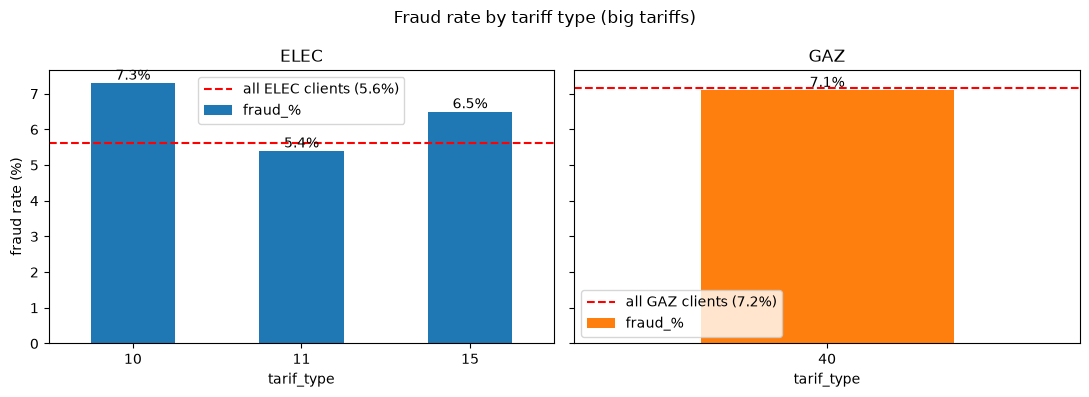

In [17]:
# only tariffs with more than 1,000 clients on that meter
big_tariffs = {m: tariff_results[m][tariff_results[m]["clients"] > 1000].sort_index() for m in meters}
side_by_side(big_tariffs, "tarif_type", "Fraud rate by tariff type (big tariffs)")

**Insight:**
- The tariffs of the two meters **do not overlap**: ELEC bills only use tariffs 8 to 29, GAZ bills only 30 to 45. So a tariff also tells us which meter a bill belongs to.
- **GAZ:** tariff **40** (61,655 clients) has **7.1%**, almost exactly the average of all gas clients (7.2%). So the "high" 7.7% of tariff 40 in notebook 06 was **a gas-meter effect, not a tariff effect**. Tariff **45** has **16.2%** (388 clients), more than twice the gas average. Tariff 30 has 11 clients, too few.
- **ELEC:** tariff **11** (120,689 clients) has 5.4% and tariff **10** (11,889 clients) 7.3%, so tariff 10 is higher. Rare tariffs (14: 11.1% with 226 clients, 12: 9.3% with 193 clients, 29: 8.7% with 277 clients) look high but are too small to trust.

**Result:** **Supported for ELEC** (tariff 10 above tariff 11, a moderate effect). **GAZ:** tariff 40 only shows the gas average. Tariff 45 is high, but a small group.
**Next step:** Keep `tarif_type` as a category (group the rare ones). We should not read tariff 40 as a fraud signal.

## Hypothesis 5: `reading_remarque` has an impact on fraud

For each remark and meter we look at all clients who got that remark **at least once on a bill of this meter**, and calculate how many of them are fraud.

In [18]:
# one row per client, meter and remark: the client got this remark at least once on this meter
remark_clients = invoice_train[["client_id", "counter_type", "reading_remarque"]].drop_duplicates()
remark_clients = remark_clients.merge(client_train[["client_id", "target"]], on="client_id")

# fraud rate per remark, for each meter
remark_results = {m: rate_table(remark_clients[remark_clients["counter_type"] == m], "reading_remarque") for m in meters}
pd.concat(remark_results, axis=1)

ELEC             GAZ        
                 clients fraud_% clients fraud_%
reading_remarque                                
0                      4     0.0       1     0.0
6                 115557     6.0   56879     7.3
7                    472     0.0      33     3.0
8                  93338     7.3   41601     8.1
9                 114720     6.4   46929     7.7

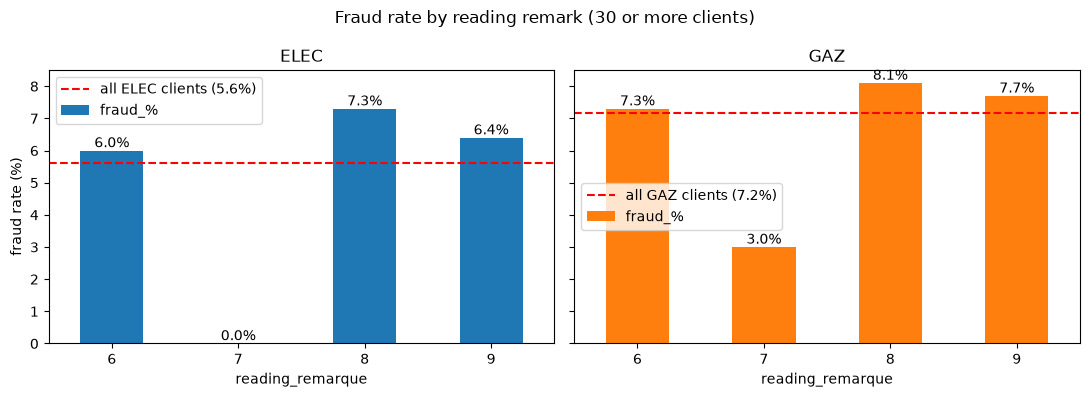

In [19]:
# only remarks with at least 30 clients in the chart
big_remarks = {m: remark_results[m][remark_results[m]["clients"] >= 30] for m in meters}
side_by_side(big_remarks, "reading_remarque", "Fraud rate by reading remark (30 or more clients)")

The agent suspected that remark 7 only means a short history. We check how many bills the remark-7 clients have on each meter, compared with all clients of that meter.

In [20]:
# compare the remark-7 clients with all clients of the meter: number of bills and fraud rate
rows = {}
for m in meters:
    # client ids with remark 7 on this meter
    r7 = remark_clients[(remark_clients["counter_type"] == m) & (remark_clients["reading_remarque"] == 7)]["client_id"]
    d = data[m]
    rows[m] = {
        "clients with remark 7": len(r7),
        "fraud % (remark 7)": round(d[d["client_id"].isin(r7)]["target"].mean() * 100, 1),
        "median bills (remark 7)": d[d["client_id"].isin(r7)]["n_bills"].median(),
        "median bills (all clients)": d["n_bills"].median(),
        # reference: the other clients with a short history (at most 5 bills)
        "fraud % (all other clients with at most 5 bills)": round(d[~d["client_id"].isin(r7) & (d["n_bills"] <= 5)]["target"].mean() * 100, 1),
        "clients with remark 7 and at most 5 bills": int(d[d["client_id"].isin(r7) & (d["n_bills"] <= 5)].shape[0]),
    }
pd.DataFrame(rows)

,ELEC,GAZ
clients with remark 7,472.0,33.0
fraud % (remark 7),0.0,3.0
median bills (remark 7),3.0,3.0
median bills (all clients),23.0,23.0
fraud % (all other clients with at most 5 bills),1.0,2.6
clients with remark 7 and at most 5 bills,431.0,31.0


**Insight:**
- Remarks **6, 8 and 9** cover almost all clients on both meters. Their rates are close to the average of the meter: ELEC 6.0%, 7.3%, 6.4% (average 5.6%) and GAZ 7.3%, 8.1%, 7.7% (average 7.2%). **Remark 8 is the highest on both meters.**
- Remark **7** is almost only an electricity remark (472 clients with ELEC bills, 33 with GAZ bills). **None of the 472 electricity clients with remark 7 is fraud.** For gas, 33 clients are too few to say anything (3.0%).
- The agent suspected that remark 7 only means a short history. This is **mostly true**: these clients have a median of only 3 bills (all clients: 23), and clients with up to 5 bills are fraud only about 1% of the time. With that rate we would expect around 4 fraud clients among the 431 remark-7 clients with up to 5 bills, so 0 is still a little low. This is a hint, not a proof.
- Remark 0 has 4 and 1 clients, so ignore it.

**Result:** **Partly supported** on both meters (remark 8 a bit high, the other remarks near the average). The remark 7 signal exists only for ELEC and is mostly a short-history effect.
**Next step:** Keep `reading_remarque` as a category. Do not trust remark 7 alone, combine it with `n_bills`.

## Hypothesis 6: a negative index difference indicates fraud

For each client and meter we count the bills where `new_index` is smaller than `old_index`, and compare the fraud rate of clients with and without such bills. 

In [21]:
# fraud rate of clients with and without a backward bill, per meter
backward_results = {m: rate_table(data[m], "has_backward").rename(index={False: "no backward bill", True: "has backward bill"}) for m in meters}
pd.concat(backward_results, axis=1)

ELEC             GAZ        
                  clients fraud_% clients fraud_%
has_backward                                     
no backward bill   133107     5.5   61908     7.2
has backward bill    1708    11.2     146    12.3

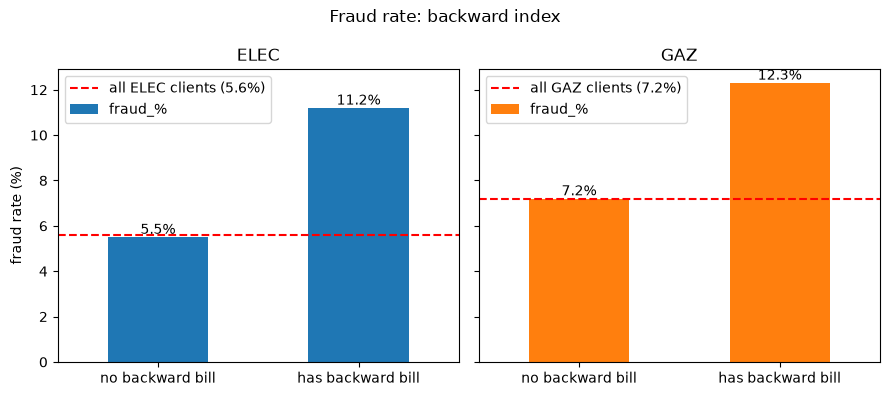

In [22]:
# chart: backward vs no backward bill, ELEC left and GAZ right
side_by_side(backward_results, "", "Fraud rate: backward index", figsize=(9, 4))

Does it get stronger with more backward bills? And inside each bill group (fraud rate in %)?

In [23]:
# group the clients by their number of backward bills (0, 1, 2-3, 4 or more)
for m in meters:
    data[m]["backward_groups"] = pd.cut(data[m]["backward_count"], [-1, 0, 1, 3, 1000], labels=["0", "1", "2-3", "4 or more"])

# does the fraud rate grow with more backward bills?
backward_count_results = {m: rate_table(data[m], "backward_groups") for m in meters}
display(pd.concat(backward_count_results, axis=1))

# backward effect inside each bill group
group_backward = pd.concat({m: rate_by_group(data[m], "has_backward", ["no backward", "has backward"]) for m in meters}, axis=1)
group_backward

ELEC             GAZ        
                clients fraud_% clients fraud_%
backward_groups                                
0                133107     5.5   61908     7.2
1                  1451    11.2     130    12.3
2-3                 228    11.0      15    13.3
4 or more            29    13.8       1     0.0

ELEC                      GAZ             
           no backward has backward no backward has backward
bill_group                                                  
1 to 10            1.6          7.6         3.5         12.5
11 to 30           5.8          8.9         7.4          8.6
31 to 50           8.1         11.7         8.9          7.5
51 or more        14.0         17.2        23.8         29.6

Many backward bills are normal rollovers: the meter shows a limited number of digits, so after 99,999 it starts again at 0. A bill is a **rollover** if `old_index` is in the top 10% of the meter range and `new_index` is in the bottom 10% (the range is 9,999, 99,999 or 999,999, depending on the meter). We first count how many backward bills are rollovers, then split the backward clients: **only rollovers** and **at least one non-rollover bill**.

In [24]:
# share of backward bills that are normal rollovers, per meter
backward_bills = invoice_train[invoice_train["backward"] == 1]
print("share of backward bills that are rollovers:")
print(backward_bills.groupby("counter_type")["rollover"].agg(["mean", "sum", "count"]).round(2).rename(columns={"sum": "rollovers", "count": "backward bills"}))

# label each client: no backward bill, only rollovers, or at least one non-rollover
def backward_type(df):
    kind = pd.Series("no backward bill", index=df.index)
    kind[df["has_backward"]] = "only rollovers"
    kind[df["has_backward_other"]] = "at least one non-rollover"
    return kind

# fraud rate of these three client groups, per meter
backward_type_results = {m: rate_table(data[m].assign(kind=backward_type(data[m])), "kind") for m in meters}
pd.concat(backward_type_results, axis=1)

share of backward bills that are rollovers:
              mean  rollovers  backward bills
counter_type                                 
ELEC          0.85       1781            2090
GAZ           0.79        137             174


ELEC             GAZ        
                          clients fraud_% clients fraud_%
kind                                                     
at least one non-rollover     266     9.8      29     3.4
no backward bill           133107     5.5   61908     7.2
only rollovers               1442    11.5     117    14.5

**Insight:**
- **ELEC:** clients with a backward bill have **11.2%** fraud (1,708 clients) vs 5.5% without. About **twice**. Inside each bill group the backward clients are always higher (for example 1.6% vs 7.6%, and 14.0% vs 17.2%).
- **GAZ:** **12.3%** vs 7.2% (about 1.7 times), the same direction, but only **146 clients** have a backward gas bill. The bill group numbers jump around (higher for 1 to 10 and 51 or more bills, lower for 31 to 50), because the groups are tiny.
- The rate does not grow much with more backward bills. Most of the effect comes from the first one.
- **Rollover check:** most backward bills are normal rollovers (85% of the electricity and 79% of the gas backward bills: the meter starts near its maximum and ends near 0). Clients whose backward bills are **all rollovers** have the high rate: ELEC **11.5%** (1,442 clients) and GAZ **14.5%** (117 clients), against 5.5% and 7.2% without a backward bill. Clients with at least one **non-rollover** backward bill: ELEC 9.8% (266 clients, still above the average) and GAZ 3.4% (29 clients, too few). 
- So the fraud signal sits mainly in the **rollovers**, the cases we first thought were harmless. We do not know why. A possible reason: a meter that wraps around is used heavily, and heavy users are more often fraud. We have not tested this. (A first version of this check used "starts at 90,000 or higher" as the rollover rule. It was too rough, because it counted rollovers of 4-digit meters as non-rollovers.)

**Result:** **Supported for ELEC.** For **GAZ** the direction is the same, but with 146 clients we cannot say much on its own.
**Next step:** Create `has_backward` and `backward_count` (from all bills, or from the ELEC bills). Add `has_rollover` as a separate feature and check if it is only a heavy-use effect.

## Hypothesis 7: outliers show fraud

For each client and meter we take the **highest** bill on that meter, group the clients by that value (same groups as in notebook 06) and compare the fraud rate.

Note: electricity is measured in kWh and gas in cubic metres, so the same number does not mean the same size on both meters.

In [25]:
# group the clients by their highest bill on this meter (same groups as in notebook 06)
labels = ["up to 1,000", "1,000 to 5,000", "5,000 to 10,000", "10,000 to 50,000", "above 50,000"]
for m in meters:
    data[m]["max_consumption_group"] = pd.cut(data[m]["max_consumption"], [-1, 1000, 5000, 10000, 50000, float("inf")], labels=labels)

# fraud rate per group, for each meter
outlier_results = {m: rate_table(data[m], "max_consumption_group") for m in meters}
pd.concat(outlier_results, axis=1)

ELEC             GAZ        
                      clients fraud_% clients fraud_%
max_consumption_group                                
up to 1,000             50820     2.6   51633     6.7
1,000 to 5,000          73542     6.8    9545     9.4
5,000 to 10,000          6711    11.6     644    11.8
10,000 to 50,000         3511    13.2     227    14.1
above 50,000              231     3.9       5     0.0

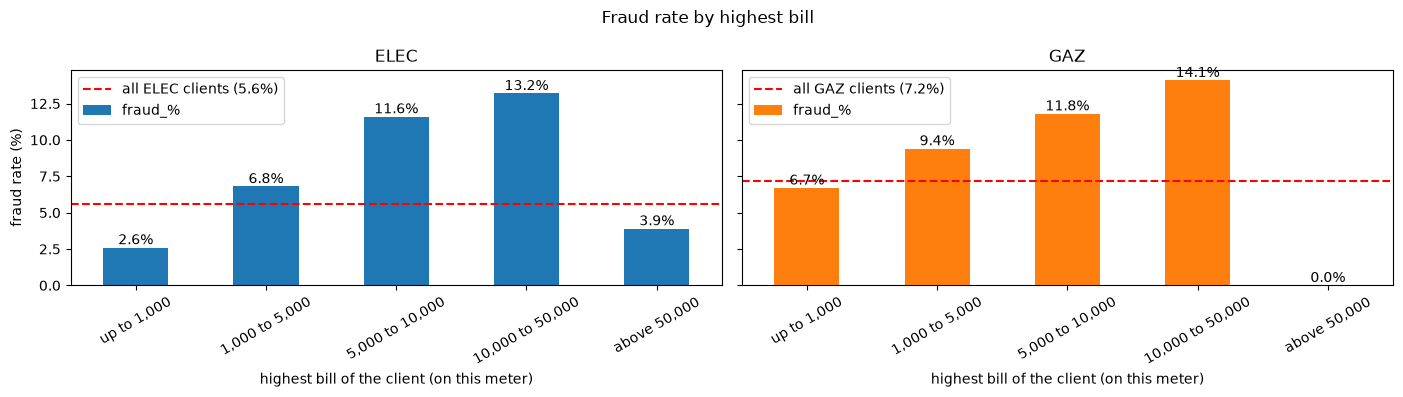

In [26]:
# chart: fraud rate by highest bill, ELEC left and GAZ right
side_by_side(outlier_results, "highest bill of the client (on this meter)", "Fraud rate by highest bill", figsize=(14, 4), rot=30)

Inside each bill group (fraud rate in %), using the biggest bill grouped in 3 steps:

In [27]:
# group the highest bill in 3 steps: up to 1,000, 1,000 to 10,000, above 10,000
for m in meters:
    data[m]["max_group3"] = pd.cut(data[m]["max_consumption"], [-1, 1000, 10000, float("inf")],
                                   labels=["up to 1,000", "1,000 to 10,000", "above 10,000"])

# fraud rate per highest-bill group inside each bill group
group_outlier = pd.concat({
    m: (data[m].groupby(["bill_group", "max_group3"], observed=True)["target"].mean().unstack() * 100).round(1)
    for m in meters}, axis=1)
group_outlier

ELEC                                      GAZ  \
max_group3 up to 1,000 1,000 to 10,000 above 10,000 up to 1,000   
bill_group                                                        
1 to 10            0.7             2.9          6.8         3.1   
11 to 30           2.6             6.9         13.6         6.9   
31 to 50           6.2             8.8         12.5         8.8   
51 or more        10.2            14.0         18.2        26.8   

                                         
max_group3 1,000 to 10,000 above 10,000  
bill_group                               
1 to 10                6.3          8.0  
11 to 30               9.7         13.7  
31 to 50               9.7          6.2  
51 or more            23.9         22.8

**Insight:**
- On **both** meters the fraud rate rises with the highest bill: ELEC 2.6%, 6.8%, 11.6%, 13.2% and GAZ 6.7%, 9.4%, 11.8%, 14.1%. The two ends are close (13.2% vs 14.1%).
- The **rise is much steeper for ELEC** (5 times from the lowest to the highest group) than for GAZ (2 times). Gas clients with small bills are already at 6.7%.
- Above 50,000 the ELEC rate drops to 3.9% (231 clients), probably errors. Gas has only 5 clients there.
- Check with a similar number of bills: for **ELEC** a higher highest bill gives a higher fraud rate in **every** bill group (for example 0.7%, 2.9%, 6.8% for 1 to 10 bills, and 10.2%, 14.0%, 18.2% for 51 or more). For **GAZ** this only holds for up to 30 bills (3.1%, 6.3%, 8.0% and 6.9%, 9.7%, 13.7%). For 31 or more bills it is flat or even falls.

**Result:** **Supported for ELEC**, also with a similar number of bills. For **GAZ** it is **partly** a bill-count effect.
**Next step:** Use the max and median consumption per client, for each meter. Keep the outliers.

## Hypothesis 8: the fraud rate differs by client category

We calculate the fraud rate of each `client_catg`, once for the clients with an electricity meter and once for the clients with a gas meter.

In [28]:
# fraud rate per client category, for each meter
catg_results = {m: rate_table(data[m], "client_catg") for m in meters}
pd.concat(catg_results, axis=1)

ELEC             GAZ        
            clients fraud_% clients fraud_%
client_catg                                
11           130859     5.5   60556     7.0
12             2298     4.0     895     4.9
51             1658    17.0     603    26.2

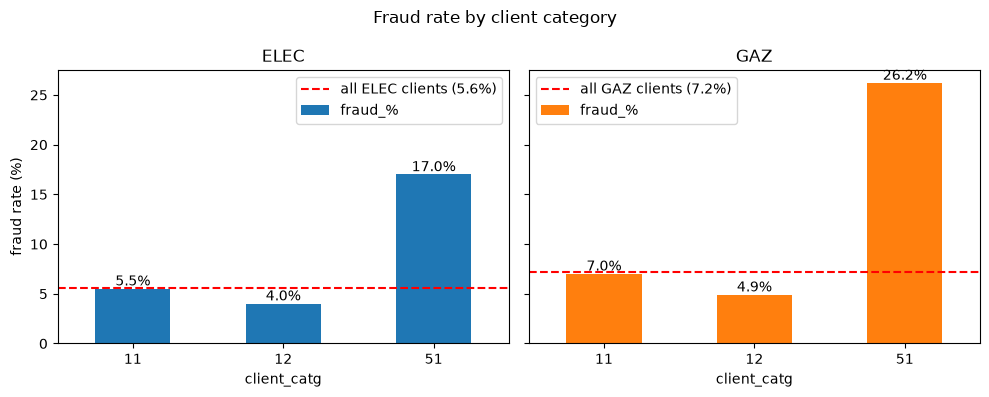

In [29]:
# chart: fraud rate by client category, ELEC left and GAZ right
side_by_side(catg_results, "client_catg", "Fraud rate by client category", figsize=(10, 4))

Inside each bill group (fraud rate in %):

In [30]:
# client category effect inside each bill group
group_catg = pd.concat({
    m: (data[m].groupby(["bill_group", "client_catg"], observed=True)["target"].mean().unstack() * 100).round(1)
    for m in meters}, axis=1)
group_catg

ELEC              GAZ           
client_catg    11   12    51    11   12    51
bill_group                                   
1 to 10       1.5  1.4   7.4   3.3  3.0  25.7
11 to 30      5.7  5.4  15.5   7.3  5.3  23.9
31 to 50      8.1  4.7  26.9   8.8  5.7  35.7
51 or more   13.3  9.5  18.9  26.3  NaN  23.4

**Insight:**
- Category **51** has the highest fraud rate on both meters: ELEC **17.0%** (1,658 clients) against 5.5% for category 11, and GAZ **26.2%** (603 clients) against 7.0%. On gas it is about **3.6 times** the gas average.
- Category 12 is a little below the average on both meters (4.0% and 4.9%).
- Inside the bill groups category 51 is the highest on both meters, with one exception: gas clients with 51 or more bills (23.4% vs 26.3%, tiny group). For ELEC it holds in every group (for example 7.4% vs 1.5%, and 26.9% vs 8.1%). For GAZ (for example 25.7% vs 3.3%, and 35.7% vs 8.8%).

**Result:** Supported on **both** meters, **strongest for gas**.
**Next step:** Keep `client_catg` as a category feature.

## Hypothesis 9: the meter setup has an impact on fraud

This hypothesis is about the difference between the two meters itself, so here the clients are split in three groups: **ELEC only**, **GAZ only** and **both**. We use **all bills** of the client for the bill groups. (Only 678 clients have gas only.)

In [31]:
# meter setup per client (ELEC only, GAZ only or both) and the number of all bills
setup_per_client = invoice_train.groupby("client_id").agg(
    meter_setup=("counter_type", lambda s: "both" if s.nunique() > 1 else s.iloc[0]),
    n_bills_all=("consumption", "size"),
).reset_index()
# add the fraud label and the bill groups, based on all bills of the client
setup = client_train[["client_id", "target"]].merge(setup_per_client, on="client_id")
setup["bill_group"] = pd.cut(setup["n_bills_all"], [0, 10, 30, 50, 1000], labels=["1 to 10", "11 to 30", "31 to 50", "51 or more"])
# clearer names for the one-meter groups
setup["meter_setup"] = setup["meter_setup"].replace({"ELEC": "ELEC only", "GAZ": "GAZ only"})

# fraud rate and median number of bills per setup
setup_result = rate_table(setup, "meter_setup")
setup_result["median bills"] = setup.groupby("meter_setup")["n_bills_all"].median()
setup_result

,clients,fraud_%,median bills
meter_setup,,,
ELEC only,73439,4.2,16.0
GAZ only,678,0.9,3.0
both,61376,7.2,52.0


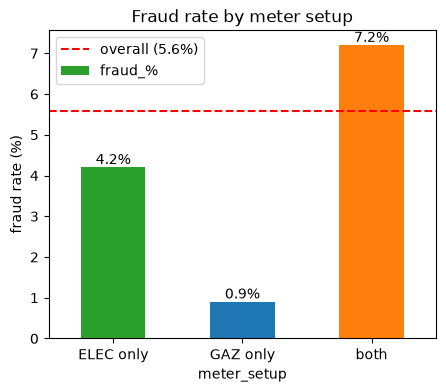

In [32]:
# bar chart of the fraud rate per meter setup
ax = setup_result["fraud_%"].plot(kind="bar", rot=0, figsize=(5, 4), color=["tab:green", "tab:blue", "tab:orange"])
ax.bar_label(ax.containers[0], fmt="%.1f%%")
# red line: fraud rate of all train clients
plt.axhline(client_train["target"].mean() * 100, color="red", linestyle="--", label="overall (5.6%)")
plt.ylabel("fraud rate (%)")
plt.title("Fraud rate by meter setup")
plt.legend()
plt.show()

Inside each bill group, so we compare clients with a similar number of bills (fraud rate in %, number of clients below):

In [33]:
# fraud rate and number of clients per setup, inside each bill group (all bills)
group_setup = pd.concat({
    "fraud %": (setup.groupby(["bill_group", "meter_setup"], observed=True)["target"].mean().unstack() * 100).round(1),
    "clients": setup.groupby(["bill_group", "meter_setup"], observed=True)["target"].count().unstack(),
}, axis=1)
group_setup

fraud %                 clients                
meter_setup ELEC only GAZ only both ELEC only GAZ only   both
bill_group                                                   
1 to 10           1.2      0.8  1.9     28769      474   4688
11 to 30          4.9      0.0  4.6     24937      126  10445
31 to 50          7.6      0.0  7.3     18404       64  14264
51 or more       12.0     14.3  8.8      1329       14  31979

Another view on the same question: a **gas meter next to an electricity meter**. For clients with an electricity meter, does it matter if they also have a gas meter? We compare inside the electricity bill groups.

In [34]:
# electricity clients only, with a flag if they also have a gas meter
elec = data["ELEC"].merge(setup[["client_id", "meter_setup"]], on="client_id")
elec["gas meter too"] = elec["meter_setup"] == "both"
# fraud rate inside the electricity bill groups, with and without a gas meter
group_gas_too = (elec.groupby(["bill_group", "gas meter too"], observed=True)["target"].mean().unstack() * 100).round(1)
group_gas_too.columns = ["ELEC only", "ELEC + GAZ"]
group_gas_too

,ELEC only,ELEC + GAZ
bill_group,,
1 to 10,1.2,2.9
11 to 30,4.9,6.8
31 to 50,7.6,8.6
51 or more,12.0,16.1


**Insight:**
- Same result as in notebook 06: clients with **both** meters have 7.2% fraud (61,376 clients), **ELEC only** 4.2% (73,439), **GAZ only** 0.9% (678). Clients with both meters have many more bills (median 52 vs 16).
- Inside the bill groups (all bills of the client) "both" and "ELEC only" are almost the same: 1.9% vs 1.2%, 4.6% vs 4.9%, 7.3% vs 7.6%, 8.8% vs 12.0%. GAZ only has too few clients.
- The new view (last table) compares electricity clients with and without a gas meter by their **electricity** bills only. Here "ELEC + GAZ" is higher in every group (for example 2.9% vs 1.2%, and 16.1% vs 12.0%). But this is **not a fair comparison**: clients with a gas meter also have gas bills, so they have more bills in total, and the number of bills is what drives fraud. The first view (all bills) is the cleaner one.

**Result:** **Not supported**, as before. Having a gas meter adds no risk of its own once the total number of bills is similar.
**Next step:** Do not use the meter setup as a feature. The number of bills (`n_bills`) is the useful one.

## Summary: gas vs electricity per hypothesis

| # | Hypothesis | ELEC | GAZ | Same for both? |
|---|-----------|------|-----|----------------|
| 1 | Region | **Supported.** 103 highest (10.3%), 101 and 301 lowest | **Supported.** Same order (rank correlation 0.89), 103 highest (12.5%) | **Yes** |
| 2 | Sudden change in consumption | **Supported.** Fraud has a 64% bigger jump, in every bill group | **Weak.** 29% bigger jump, only for up to 30 bills | **No**, ELEC is stronger |
| 3 | Index mismatch | **Weak.** 9.2% vs 5.5%, mostly for up to 30 bills | **Not supported.** 7.9% vs 7.1%, no pattern | **No**, ELEC only |
| 4 | Tariff type | **Supported (moderate).** Tariff 10 (7.3%) above 11 (5.4%) | Tariff 40 (7.1%) is just the gas average. Tariff 45 is high (16.2%, 388 clients) | **No.** The tariff 40 effect in notebook 06 was a gas-meter effect |
| 5 | `reading_remarque` | **Partly.** Remark 8 highest, remark 7 (0 of 472) mostly short history | **Partly.** Remark 8 highest, remark 7 has only 33 clients | **Partly**, remark 7 is an ELEC remark |
| 6 | Negative index difference | **Supported.** 11.2% vs 5.5%, mostly from rollovers | Same direction (12.3% vs 7.2%), but only 146 clients | **Same direction**, gas not reliable alone |
| 7 | Outliers | **Supported**, also in each bill group (2.6% to 13.2%) | Rises too (6.7% to 14.1%), but flat for 31 or more bills | **Partly**, steeper for ELEC |
| 8 | Client category | **Supported.** Category 51: 17.0% | **Supported, stronger.** Category 51: 26.2% | **Yes** |
| 9 | Meter setup | **Not supported**, bill count explains it | (same test) | **Not supported** |

**What we learn:**
- **Same for both meters:** region (1) and client category (8) work on both. These can stay as plain category features.
- **Mostly an electricity signal:** sudden change (2), index mismatch (3) and outliers (7) are clearly visible on ELEC and weak or not visible on GAZ. Calculating these features **per meter** keeps the electricity signal clean.
- **Gas is not a risk factor by itself:** gas clients have a higher average (7.2%), and tariff 40 only repeats that. We should not read the high tariff 40 rate as a tariff effect.
- **Small groups:** many gas results rest on few clients (146 with a backward bill, 33 with remark 7, 347 with 51 or more bills). We should treat those with care.
- **Limit of this analysis:** the label is per client, so we cannot say which of the two meters was manipulated. For clients with both meters we see the same label twice.

**Next step:** In feature engineering calculate the consumption and index features per meter (`_elec`, `_gaz`) next to the total ones, and let the model decide. If this is accepted by the team, we update `hypotheses.md` and `protocol.md`.